# 01 · Exploratory Data Analysis – RetailPulse
**Dataset:** UCI *Online Retail II* (1,067,371 raw transactions, 1 Dec 2009 → 9 Dec 2011) · **Goals (Day 1–2):** dataset selection, distributions, missing values, correlation heat-map, cleaning decisions and the engineered columns.

> Run `make pipeline` first. The raw CSV is only needed for the *missing-value audit* cell (it is skipped if the file is absent).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from retailpulse import config
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
PAL = ["#7C5CFF", "#22D3EE", "#34D399", "#FBBF24", "#FB7185"]
P = config.DATA_PROC
def J(n): return json.loads((config.REPORTS / n).read_text())


## 1. Why this dataset?
It is a *real* transactional log (not synthetic) that contains all three analytical grains the brief asks for: **sales** (invoice lines), **customers** (IDs, wholesalers vs. retail) and **products** (≈4.7k SKUs). It spans two Christmas seasons, which makes seasonality/forecasting non-trivial. It has **no inventory table**, so stock levels are simulated and labelled as such.

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


exact duplicate rows: 34335
cancellations (Invoice starts with 'C'): 19494
quantity <= 0: 22950 | price <= 0: 6207
StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67


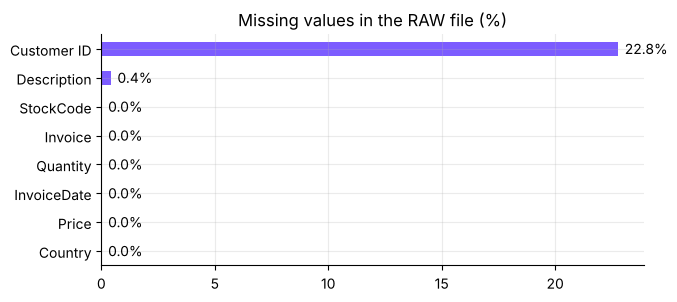

In [2]:
raw_path = config.RAW_FILE
if raw_path.exists():
    raw = pd.read_csv(raw_path, dtype={"Invoice": str, "StockCode": str})
    print(raw.shape)
    miss = raw.isna().mean().mul(100).sort_values(ascending=False)
    display(raw.head())
    ax = miss.plot.barh(color=PAL[0], figsize=(7, 3)); ax.set_title("Missing values in the RAW file (%)"); ax.invert_yaxis()
    for i, v in enumerate(miss): ax.text(v + .3, i, f"{v:.1f}%", va="center")
    print("exact duplicate rows:", raw.duplicated().sum())
    print("cancellations (Invoice starts with 'C'):", raw["Invoice"].str.startswith("C").sum())
    print("quantity <= 0:", (raw["Quantity"] <= 0).sum(), "| price <= 0:", (raw["Price"] <= 0).sum())
    print(raw["StockCode"][~raw["StockCode"].str.match(r"^\d{5}")].value_counts().head(8).to_string())
else:
    print("raw file not present - skipping raw audit; see reports/etl_report.json lineage below")

**Findings →** 22.8 % of lines have no `Customer ID` (guest checkouts) – kept for *demand* modelling, excluded from CRM models; ≈34k exact duplicates; ≈19k cancellations (split into a returns table); non-product service codes (`POST`, `DOT`, `M`, `BANK CHARGES`, `AMAZONFEE` …) removed.

## 2. ETL lineage (what each cleaning step removed)

In [3]:
rep = J("etl_report.json")
lin = pd.DataFrame(rep["lineage"])
display(lin[["step", "rows_before", "rows_after", "rows_removed", "note"]])
print(f"retained {rep['retention_pct']}%  |  quality checks passed: {rep['quality_passed']}  |  custom column: {rep['custom_column']}")

,step,rows_before,rows_after,rows_removed,note
0,extract,1067371,1067371,0,raw rows loaded
1,drop unparsable dates,1067371,1067371,0,
2,drop exact duplicate rows,1067371,1033036,34335,same invoice/item/qty/time/price
3,split cancellations -> returns table,1033036,1013932,19104,invoice prefix 'C'
4,drop bad-debt adjustments,1013932,1013926,6,invoice prefix 'A'
5,drop qty<=0 or price<=0,1013926,1007912,6014,stock write-offs / free samples
6,drop non-product service codes,1007912,1003338,4574,"postage, fees, manual, samples"
7,fix / drop missing descriptions,1003338,1003338,0,back-filled from StockCode mode
8,drop duplicates after text normalisation,1003338,1003336,2,"same line, different description text"
9,winsorise quantity,1003336,1003336,0,948 lines capped at p99.9 = 500 units


retained 94.0%  |  quality checks passed: 27/27  |  custom column: region_group


## 3. Distributions (clean data)

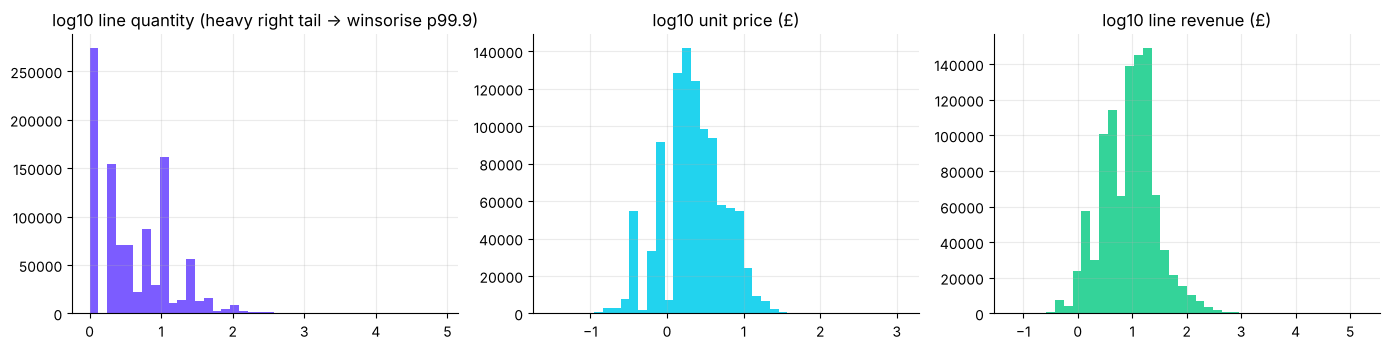

         quantity  quantity_capped  unit_price     revenue
count  1003336.00       1003336.00  1003336.00  1003336.00
mean        11.15            10.25        3.34       19.58
std        128.74            28.34        4.75      199.98
min          1.00             1.00        0.03        0.06
50%          4.00             4.00        2.10       10.08
99%        108.00           108.00       16.95      179.00
99.9%      500.00           500.00       34.95      763.73
max      80995.00           500.00     1157.15   168469.60


In [4]:
sales = pd.read_parquet(P / "clean_transactions.parquet", columns=["quantity", "quantity_capped", "unit_price", "revenue", "date", "region_group", "country", "is_guest", "invoice_no", "customer_key", "dow", "hour"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(np.log10(sales["quantity"]), bins=40, color=PAL[0]); ax[0].set_title("log10 line quantity (heavy right tail → winsorise p99.9)")
ax[1].hist(np.log10(sales["unit_price"]), bins=40, color=PAL[1]); ax[1].set_title("log10 unit price (£)")
ax[2].hist(np.log10(sales["revenue"].clip(lower=.01)), bins=40, color=PAL[2]); ax[2].set_title("log10 line revenue (£)")
plt.tight_layout(); plt.show()
print(sales[["quantity", "quantity_capped", "unit_price", "revenue"]].describe(percentiles=[.5, .99, .999]).round(2))

## 4. Time structure – the key to forecasting

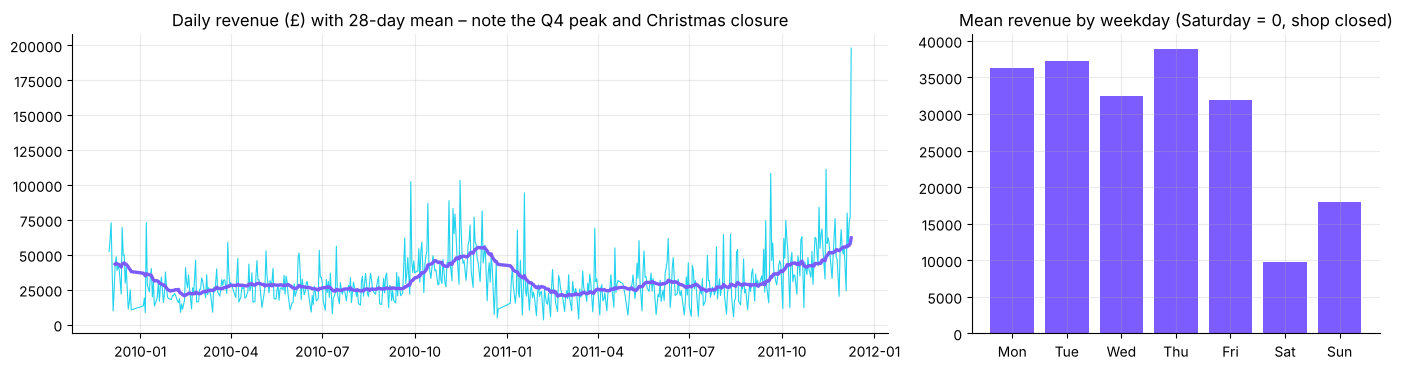

calendar days: 739 | trading days: 604 | closed (Sat, bank holidays, 24 Dec-3 Jan): 135


In [5]:
d = pd.read_parquet(P / "daily_sales.parquet")
o = d[d["is_open"].astype(bool)]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(o["date"], o["revenue"], lw=.8, color=PAL[1]); ax[0].plot(o["date"], o["revenue"].rolling(28, min_periods=7).mean(), lw=2.4, color=PAL[0])
ax[0].set_title("Daily revenue (£) with 28-day mean – note the Q4 peak and Christmas closure")
dow = o.groupby(o["date"].dt.day_name())["revenue"].mean().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
ax[1].bar(dow.index.str[:3], dow.values.astype(float), color=PAL[0]); ax[1].set_title("Mean revenue by weekday (Saturday = 0, shop closed)")
plt.tight_layout(); plt.show()
print("calendar days:", len(d), "| trading days:", int(d["is_open"].sum()), "| closed (Sat, bank holidays, 24 Dec-3 Jan):", int((~d["is_open"].astype(bool)).sum()))

region_group
Europe           13.0
Rest of World     1.5
UK               85.5
Unspecified       0.1
Name: % of revenue, dtype: float64

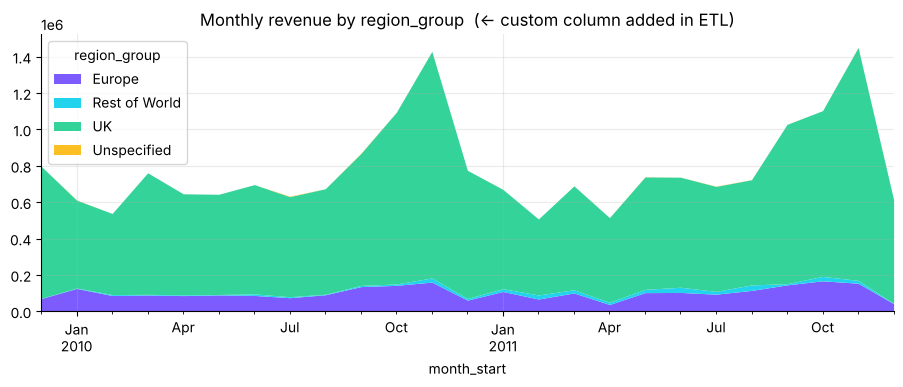

In [6]:
mr = pd.read_parquet(P / "monthly_region.parquet")
piv = mr.pivot(index="month_start", columns="region_group", values="revenue").fillna(0)
ax = piv.plot.area(figsize=(11, 3.6), color=PAL[:piv.shape[1]], lw=0); ax.set_title("Monthly revenue by region_group  (← custom column added in ETL)")
display((piv.sum() / piv.sum().sum() * 100).round(1).rename("% of revenue"))

## 5. Customer-level features & correlation heat-map

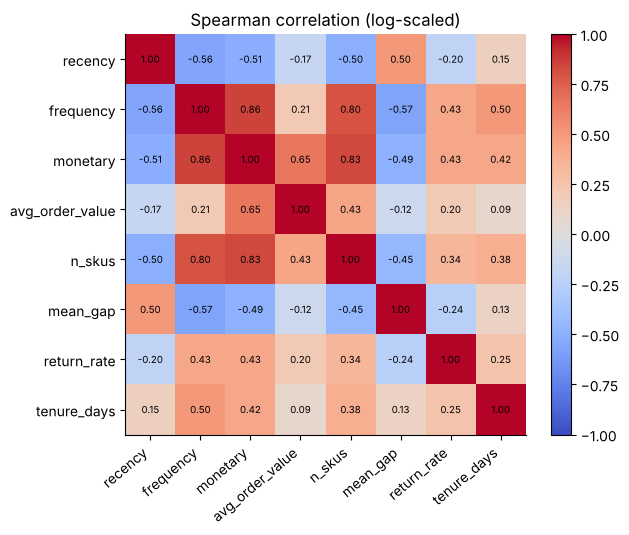

Customers: 5852 | median orders: 3.0 | top 1 pct of customers hold 32% of revenue


In [7]:
c = pd.read_parquet(P / "customers.parquet")
cols = ["recency", "frequency", "monetary", "avg_order_value", "n_skus", "mean_gap", "return_rate", "tenure_days"]
corr = np.log1p(c[cols].clip(lower=0)).corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.2)); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=40, ha="right"); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Spearman correlation (log-scaled)"); plt.show()
share = c.nlargest(len(c) // 100, "monetary")["monetary"].sum() / c["monetary"].sum() * 100
print(f"Customers: {len(c)} | median orders: {c['frequency'].median()} | top 1 pct of customers hold {share:.0f}% of revenue")

**Findings →** (1) frequency, monetary and SKU breadth are strongly correlated (wholesalers buy often, big and broad) → one `Champions` segment drives most revenue; (2) recency is negatively related to frequency; (3) revenue is extremely concentrated, so we log-scale before clustering; (4) strong weekly + annual seasonality and a Christmas closure → trading-day calendar + holiday effects in the forecasters.